# 3장 2강: 규제 — L1(Lasso), L2(Ridge), ElasticNet

## 실습 목표

이번 실습에서는 **Ames Housing** 데이터를 이용하여 Ridge, Lasso, ElasticNet 규제가 회귀계수와 일반화 성능에 어떤 영향을 주는지 확인합니다.

- 규제가 계수의 크기를 줄이는 이유를 이해합니다.
- `alpha` 변화에 따라 Ridge의 계수 크기와 Test 성능이 어떻게 달라지는지 확인합니다.
- Lasso가 일부 계수를 정확히 0으로 만드는지 확인합니다.
- ElasticNet이 L1과 L2를 함께 사용하는 모델이라는 점을 확인합니다.
- Ridge / Lasso / ElasticNet의 계수와 Test 성능을 비교합니다.

> 이 실습에서는 3장 2강 교안에서 다룬 규제, alpha, Lasso, Ridge, ElasticNet, StandardScaler, R² 비교만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- numpy
- matplotlib
- scikit-learn
- 데이터: `Ames_Housing.csv`

### 분석 목표

주택 특성을 이용하여 `SalePrice`를 예측하는 회귀 문제입니다.

### 사용할 특성

규제에 따른 계수 변화를 비교하기 위해 결측치가 없는 숫자형 특성 중 다음 12개를 사용합니다.

- `OverallQual`
- `GrLivArea`
- `GarageCars`
- `GarageArea`
- `TotalBsmtSF`
- `1stFlrSF`
- `2ndFlrSF`
- `FullBath`
- `TotRmsAbvGrd`
- `YearBuilt`
- `YearRemodAdd`
- `Fireplaces`

예측 대상은 `SalePrice`입니다.

## 실습 준비

규제는 계수의 크기를 기준으로 벌점을 주기 때문에 특성의 스케일을 맞추는 과정이 중요합니다.

이번 실습에서는 다음 순서로 데이터를 준비합니다.

1. Ames Housing 데이터 불러오기
2. 사용할 특성과 `SalePrice` 선택
3. Train / Test 분리
4. `StandardScaler`를 이용한 특성 표준화

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.metrics import r2_score

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "FullBath",
    "TotRmsAbvGrd",
    "YearBuilt",
    "YearRemodAdd",
    "Fireplaces"
]

X = house[features]
y = house["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train 크기:", X_train_scaled.shape)
print("Test 크기:", X_test_scaled.shape)

Train 크기: (1168, 12)
Test 크기: (292, 12)


---

# 필수 1. Ridge와 alpha에 따른 계수 축소

## 배경

Ridge는 **L2 규제**를 사용합니다.

Ridge는 계수의 제곱합에 벌점을 주기 때문에 큰 계수를 더 강하게 억제하고, 모든 계수를 0에 가깝게 줄이는 특징이 있습니다.

## 문제 1. 여러 alpha 값에서 Ridge를 비교하세요.

### 요구사항

다음 alpha 값을 사용합니다.

```python
alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]
```

각 alpha에 대해 다음을 수행합니다.

1. `Ridge(alpha=alpha)` 모델을 만듭니다.
2. Train 데이터로 학습합니다.
3. Test 데이터를 예측합니다.
4. Test R²를 계산합니다.
5. `abs(model.coef_).sum()`으로 전체 계수 크기를 확인합니다.
6. 결과를 DataFrame으로 정리합니다.

### 확인 포인트

- alpha가 커질수록 규제 강도가 강해지는가?
- alpha가 커질수록 전체 계수 크기가 작아지는가?
- alpha가 너무 커지면 Test 성능이 낮아질 수 있는가?

,alpha,test_r2,coef_abs_sum,coef_max
0,0.001,0.799357,102172.590850,25345.979633
1,0.010,0.799357,102172.463666,25345.663528
2,0.100,0.799355,102171.096834,25342.502352
3,1.000,0.799331,102149.831747,25310.894717
4,10.000,0.799056,101725.431454,24999.870336
5,100.000,0.795593,97390.120153,22445.469075


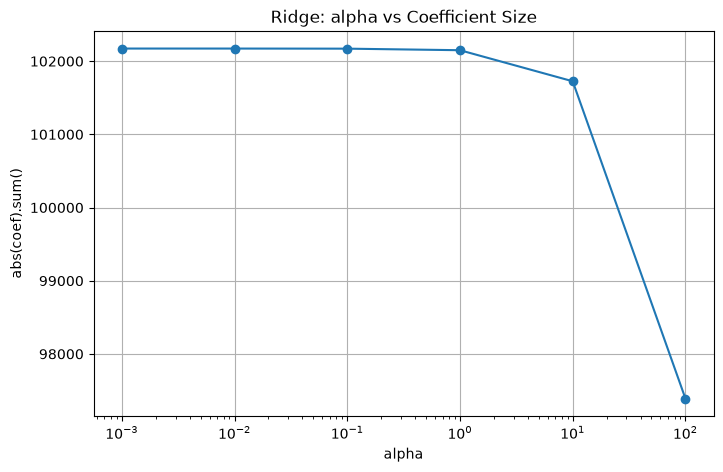

In [8]:
# TODO
# 여러 alpha 값에 대해 Ridge의 Test R²와 계수 크기를 비교하세요.

alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

results = []

for alpha in alpha_values:
    model = Ridge(alpha=alpha)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    # test_r2 = r2_score(y_test, y_pred)
    # coefficient_size = abs(model.coef_).sum()
    # ridge_results.append = (("alpha", alpha), ("test_r2", test_r2), ("coefficient_size", coefficient_size))
    results.append({
        "alpha": alpha,
        "test_r2": r2_score(y_test, y_pred),
        "coef_abs_sum": abs(model.coef_).sum(),
        "coef_max": abs(model.coef_).max()
    })
# ridge_results_df = pd.DataFrame(results)
ridge_df = pd.DataFrame(results)

display(ridge_df)

plt.figure(figsize=(8, 5))

plt.plot(ridge_df["alpha"], ridge_df["coef_abs_sum"], marker="o")

plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("abs(coef).sum()")
plt.title("Ridge: alpha vs Coefficient Size")
plt.grid()

plt.show()

#### 실행결과
| alpha | Test R² | 계수 절대값 합 | 내용 |
|---:|---:|---:|---|
|0.001|0.7994|102172|규제가 가장 약한 설정의 값|
|0.01|0.7994|102172|앞서 규제가 가장 약했던 설정의 값과 계수가 일치|
|0.1|0.7994|102171|규제는 지속적으로 커졌지만 여전히 가장 약했던 설정의 계수와 거의 일치|
|1|0.7994|102149|계수 합이 조금 감소했으며 R²값이 낮아짐|
|10|0.7990|101725|계수 축수가 뚜렸하며, R²이 낮아짐|
|100|0.7953|97390|이번 후보중 계수의 합이 가장 낮으며 R²값도 가장 낮음|
#### -> 규제를 강화하면서 계수의 전체 크기가 점차 감소했으나 Test의 성능이 나아지지 않았다.

### Q1. alpha가 커질수록 Ridge 계수는 일반적으로 어떻게 변하나요?
**답변:**  
#### -> 일반적으로 계수의 절대값이 작아진다.
#### -> Ridge는 모든 계수를 한번에 0으로 바꾸지 않고 0에 가까운 방향으로 축소하려고 한다.



<!-- |0.001|0.7984|102172|규제가 가장 약한 설정의 값|
|0.01|0.7984|102172|앞서 규제가 가장 약했던 설정의 값과 계수가 일치|
|0.1|0.7984|102171|규제는 지속적으로 커졌지만 여전히 가장 약했던 설정의 계수와 거의 일치|
|1|0.7984|102149|계수 합이 조금 감소했으며 R²값이 낮아짐|
|10|0.7980|101725|계수 축수가 뚜렸하며, R²이 낮아짐|
|100|0.7943|97390|이번 후보중 계수의 합이 가장 낮으며 R²값도 가장 낮음| -->


### Q2. alpha가 너무 크면 어떤 문제가 발생할 수 있나요?
**답변:**  
#### -> 중요한 특성의 계수를 지나치게 줄여서 학습에 충분한 힌트를 얻지 못할 수 있다.
#### 즉, 과소적합이 발생할 수 있다.

---

# 필수 2. Lasso와 ElasticNet의 계수 변화

## 문제 1. Lasso에서 0이 되는 계수를 확인하세요.

### 배경

Lasso는 **L1 규제**를 사용하며, 중요하지 않은 특성의 계수를 정확히 0으로 만들 수 있습니다.

이번에는 규제 강도를 충분히 높여 Lasso의 변수 선택 효과를 직접 확인합니다.

### 요구사항

1. `Lasso(alpha=1000, max_iter=10000)` 모델을 만듭니다.
2. Train 데이터로 학습합니다.
3. 각 특성의 계수를 DataFrame으로 만듭니다.
4. 계수가 0인 특성의 개수를 계산합니다.
5. Test R²를 계산합니다.

### 확인 포인트

- 일부 계수가 정확히 0이 되는가?
- Ridge와 달리 Lasso가 변수 선택 효과를 갖는 이유를 이해했는가?

In [9]:
# TODO
# Lasso(alpha=1000)를 학습하고 계수와 0 계수 개수를 확인하세요.

lasso = Lasso(alpha=1000, max_iter=10000)
lasso.fit(X_train_scaled, y_train)

lasso_coef_df = pd.DataFrame({
    "feature": features,
    "coef": lasso.coef_
})

lasso_coef_df["is_zero"] = lasso_coef_df["coef"] == 0

display(lasso_coef_df)

zero_count = (lasso.coef_ == 0).sum()

print("전체 특성 수:", len(features))
print("계수가 0인 특성 수:", zero_count)
print("0이 된 특성:", lasso_coef_df.loc[lasso_coef_df["is_zero"], "feature"].tolist())

y_pred = lasso.predict(X_test_scaled)
print("\nTest R2:", r2_score(y_test, y_pred))

,feature,coef,is_zero
0,OverallQual,25520.693859,False
1,GrLivArea,21419.631042,False
2,GarageCars,6820.209072,False
3,GarageArea,4370.090292,False
4,TotalBsmtSF,7305.573442,False
5,1stFlrSF,3521.096689,False
6,2ndFlrSF,0.000000,True
7,FullBath,-0.000000,True
8,TotRmsAbvGrd,83.200163,False
9,YearBuilt,6966.923170,False


전체 특성 수: 12
계수가 0인 특성 수: 2
0이 된 특성: ['2ndFlrSF', 'FullBath']

Test R2: 0.7960182963880562


#### 결과
#### OverallQual(품질)컬럼의 계수 25520의 의미 : 품질이 높을수록 예측 가격이 높아지는 방향, 그 강도
#### GrLivArea(차고)컬럼의 계수	21419의 의미 : 지상 면적의 정보도 예측 가격에 양의 계수로 반영되고 있다.
#### 2ndFlrSF(2층면적)컬럼의 계수 0.00의 의미 : 이 모델에서 이 2층면적의 직접적인 기여도는 0이다.
#### FullBath(욕실) 컬럼의 계수	-0.00의 의미 : 이 모델에서 욕실은 예특 가격에 직접적인 기여도가 0이다.

#### 0인 계수가 2개인 것의 의미
#### 전체 12개의 특성중 2개의 특성이 0의 특징을 보임
#### 따라서 이 두열의 값이 바뀌거나 제거되어도 나머지 10개의 열이 같다면 모델의 결과는 달라지지 않음

#### 게수 0은 그러면 모델링할때 삭제해도 무방하나?
#### -> 2층 면적이나 욕실 수는 계수가 없어서 주택의 가격과 관련이 없은거 아닌가?
#### -> 데이터 분할, 규제 강도의 변화, x의 변화가 있는 경우 계수가 0이 아닐수도 있음.


### Q3. Lasso에서 계수가 0이 된다는 것은 어떤 의미인가요?

**답변:**  
#### -> 해당 특성(x)가 최종 예측식에서 영향을 주지 않는다는 의미
#### -> Lasso의 특징은 중요도가 낮다고 판단한 특성을 자동으로 모델의 힌트로 사용하지 않음(제거하는 효과)

## 문제 2. ElasticNet을 학습하고 L1/L2 혼합을 확인하세요.

### 배경

ElasticNet은 L1과 L2 규제를 함께 사용합니다.

`l1_ratio`는 두 규제의 비율을 조절합니다.

- `l1_ratio`가 1에 가까움 → Lasso 성격이 강함
- `l1_ratio`가 0에 가까움 → Ridge 성격이 강함

### 요구사항

1. `ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)` 모델을 만듭니다.
2. Train 데이터로 학습합니다.
3. Test R²를 계산합니다.
4. 각 특성의 계수를 확인합니다.

### 확인 포인트

- `alpha`와 `l1_ratio`의 역할을 구분할 수 있는가?
- ElasticNet이 Lasso와 Ridge의 성격을 함께 가진다는 점을 설명할 수 있는가?

In [10]:
# TODO
# ElasticNet(alpha=0.1, l1_ratio=0.5)을 학습하세요.

elastic = ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
elastic.fit(X_train_scaled, y_train)

y_pred = elastic.predict(X_test_scaled)

print("Test R2:", r2_score(y_test, y_pred))
print("계수가 0인 특성 수:", (elastic.coef_ == 0).sum())
print("전체 계수 크기:", abs(elastic.coef_).sum())

elastic_coef_df = pd.DataFrame({
    "feature": features,
    "coef": elastic.coef_
})

display(elastic_coef_df)

Test R2: 0.7972913023796784
계수가 0인 특성 수: 0
전체 계수 크기: 99258.8442523689


,feature,coef
0,OverallQual,23514.629015
1,GrLivArea,12670.768121
2,GarageCars,6785.127803
3,GarageArea,5137.437024
4,TotalBsmtSF,8016.089858
5,1stFlrSF,9237.815373
6,2ndFlrSF,6873.818086
7,FullBath,-1895.877032
8,TotRmsAbvGrd,2541.484569
9,YearBuilt,8072.285509


#### l1_ratio=0.5 : L1항의 앞에 0.5, L2의 제곱합 앞에는 0.025, r=0.5라는 의미는 두 규제의 혼합비율을 중간으로 쓰겠다는 의미

#### 결과
#### OverallQual(품질)칼럼의 계수 23514의 의미 : 양의 계수중 가장 큰 값, 품질 정보가 가격예측에 가장 크게 반영
#### GrLivArea(지상면적)의 컬럼 계수 12670의 의미 : 양의 계수 중 두번째로 큰값, 면적도 계격예측에 크게 반영
#### 2ndFlrSF(2층면적)칼럼 계수	6873의 의미 : Lasso에서는 0이었는데 현재에서는 가격예측에 기여
#### FullBath(욕실)칼럼의 계수 -1895의 의미 : 다른 입력이 같다면 가격예측에 음의 영향을 보인다.


### Q4. `alpha`와 `l1_ratio`는 각각 무엇을 조절하나요?

**답변:**  
#### - alpha: 전체 규제의 총 강도
#### - l1_ratio: 규제 안에서 L1과 L2의 비율
#### - -> l1_ratio가 1에 가까워질수록 Lasso, 0에 가까워질수록 Ridge 성향이 강해진다.

---

# 과제 1. 다중공선성 진단과 Ridge / Lasso / ElasticNet 비교

## 배경

같은 Train/Test 데이터에서 세 규제 모델을 비교합니다. 성취도 평가항목에 맞춰, 비교 전에 **다중공선성의 계수 해석 영향과 VIF 진단·처치 선택**을 추가합니다.

다중공선성은 입력 특성들이 서로 강한 선형 관계를 갖는 상황입니다. VIF는 한 특성을 나머지 특성으로 설명할 때 구한 결정계수 R²를 이용해 `1 / (1 - R²)`로 계산합니다. 이때 예측 대상은 `SalePrice`가 아니라 **진단할 입력 특성 하나**이며, 보조 회귀에는 절편을 포함합니다.

## 요구사항

### A. 다중공선성 진단과 처치 방향 선택

1. **Train의 입력 특성만** 이용해 특성별 VIF를 계산하고 내림차순 표 `vif_df`를 출력합니다. 기존 `X_train_scaled`를 사용해도 됩니다. 표준화는 특성 간 선형 관계 자체를 제거하지 않습니다.
2. 이번 과제에서는 `VIF < 5`: 상대적으로 낮음, `5 ≤ VIF < 10`: 주의, `VIF ≥ 10`: 높은 수준으로 분류합니다. 이는 절대적 삭제 규칙이 아닌 실습용 판단 기준입니다.
3. 주의·높은 수준인 특성을 특성명과 VIF로 제시합니다. 없으면 없다고 작성합니다. 완전한 선형 중복으로 VIF가 무한대인 경우 높은 수준으로 해석합니다. 상수 특성의 VIF는 정의하기 어려우므로 별도로 표시합니다.
4. 다중공선성이 계수의 크기·부호·안정성과 개별 변수 해석에 미치는 영향을 설명합니다.
5. 특성의 의미와 VIF 결과를 근거로 **변수 제거·결합·규제 중 한 가지 처치 방향**을 선택하고 대상·이유·한계를 설명합니다. 높은 VIF가 없으면 불필요한 제거를 하지 않는 이유와 기존 규제 비교의 목적을 설명해도 됩니다. 제거·결합의 추가 구현은 요구하지 않습니다.

### B. 기존 규제 모델 비교

다음 설정을 그대로 사용합니다.

```python
Ridge(alpha=1.0)
Lasso(alpha=1000, max_iter=10000)
ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
```

1. 세 모델을 동일한 표준화 Train 데이터로 학습합니다.
2. 동일한 Test 데이터의 R²를 계산합니다.
3. 전체 계수 크기 `abs(coef_).sum()`과 계수가 정확히 0인 개수를 계산합니다.
4. 결과를 `comparison_df`로 정리하고, 특성별 계수를 `task_coef_df`로 출력합니다.
5. Test R²와 계수 처리 차이를 함께 설명하고 Q5~Q9에 답합니다.

> Test 점수는 지정된 세 설정의 결과를 비교·해석하는 데 사용합니다. 이 점수를 보고 변수를 제거하거나 alpha를 반복 조정하지 않습니다. 실제 모델 선택·튜닝에는 Train 내부 검증 또는 CV가 필요합니다.

### 확인 포인트

- Train 입력 특성만 사용하여 VIF를 계산했는가?
- 기준과 실제 수치를 근거로 주의할 특성을 판단했는가?
- 다중공선성의 계수 해석 영향과 처치 선택 이유를 설명했는가?
- 규제가 입력 특성의 VIF 자체를 낮추는 것은 아님을 구분했는가?
- 같은 데이터에서 세 모델의 Test R²·계수 크기·0 계수 개수를 비교했는가?


In [11]:
# TODO
# A. Train 특성별 VIF 계산 및 판단
# B. 기존 세 규제 모델 비교 및 특성별 계수 표 출력
# Q5~Q9 답변 작성

# A. Train 특성별 VIF 계산 및 판정
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=features)

vif_rows = []

for col in features:
    others = [c for c in features if c != col]

    aux_model = LinearRegression()
    aux_model.fit(X_train_scaled_df[others], X_train_scaled_df[col])

    r2_aux = aux_model.score(X_train_scaled_df[others], X_train_scaled_df[col])

    if r2_aux >= 1:
        vif = np.inf
    else:
        vif = 1 / (1 - r2_aux)

    vif_rows.append({
        "feature": col,
        "r2_aux": r2_aux,
        "vif": vif
    })

vif_df = pd.DataFrame(vif_rows).sort_values("vif", ascending=False).reset_index(drop=True)


def judge_vif(v):
    """VIF 값을 실습 기준(5 미만 / 5 이상 10 미만 / 10 이상)으로 분류합니다."""
    if v < 5:
        return "낮음"
    elif v < 10:
        return "주의"
    else:
        return "높음"


vif_df["판정"] = vif_df["vif"].apply(judge_vif)

display(vif_df)

print("주의(5 <= VIF < 10):", vif_df.loc[vif_df["판정"] == "주의", "feature"].tolist())
print("높음(VIF >= 10)    :", vif_df.loc[vif_df["판정"] == "높음", "feature"].tolist())


# B. 세 규제 모델 비교
task_models = {
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1000, max_iter=10000),
    "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
}

compare_rows = []
coef_table = {"feature": features}

for name, model in task_models.items():
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    compare_rows.append({
        "model": name,
        "test_r2": r2_score(y_test, y_pred),
        "coef_abs_sum": abs(model.coef_).sum(),
        "zero_coef_count": int((model.coef_ == 0).sum())
    })

    coef_table[name] = model.coef_

comparison_df = pd.DataFrame(compare_rows)
task_coef_df = pd.DataFrame(coef_table)

display(comparison_df)
display(task_coef_df)

,feature,r2_aux,vif,판정
0,GrLivArea,0.992235,128.776832,높음
1,2ndFlrSF,0.989085,91.620664,높음
2,1stFlrSF,0.986410,73.585999,높음
3,GarageCars,0.810996,5.290892,주의
4,GarageArea,0.801292,5.032498,주의
5,TotalBsmtSF,0.736352,3.792935,낮음
6,TotRmsAbvGrd,0.699992,3.333240,낮음
7,OverallQual,0.628059,2.688595,낮음
8,YearBuilt,0.581470,2.389316,낮음
9,FullBath,0.552439,2.234330,낮음


주의(5 <= VIF < 10): ['GarageCars', 'GarageArea']
높음(VIF >= 10)    : ['GrLivArea', '2ndFlrSF', '1stFlrSF']


,model,test_r2,coef_abs_sum,zero_coef_count
0,Ridge,0.799331,102149.831747,0
1,Lasso,0.796018,88648.006135,2
2,ElasticNet,0.797291,99258.844252,0


,feature,Ridge,Lasso,ElasticNet
0,OverallQual,25310.894717,25520.693859,23514.629015
1,GrLivArea,13960.707641,21419.631042,12670.768121
2,GarageCars,7041.543409,6820.209072,6785.127803
3,GarageArea,4382.957511,4370.090292,5137.437024
4,TotalBsmtSF,7238.590424,7305.573442,8016.089858
5,1stFlrSF,10011.019199,3521.096689,9237.815373
6,2ndFlrSF,7098.896701,0.000000,6873.818086
7,FullBath,-3154.791944,-0.000000,-1895.877032
8,TotRmsAbvGrd,1602.125673,83.200163,2541.484569
9,YearBuilt,8343.117317,6966.923170,8072.285509


### Q5. Ridge와 Lasso의 가장 큰 계수 처리 차이는 무엇인가요?

**답변:**
Ridge : 계수를 0으로 만들지 않고 0에 가깝게 줄인다. 계수가 클수록 큰 계수를 깎는 데 집중하고, 이미 작아진 계수는
거의 건드리지 않아서 0 근처까지만 가고 멈춘다.
Lasso : 일부 계수를 정확히 0으로 만든다. 계수가 크든 작든 같은 방식으로 계수를 깎아내어 작아져도 아예 0으로 만들어서 그 특성을 식에서 제외하고자 한다. 
결과적으로 Ridge는 특성을 모두 남기고, Lasso는 쓸 특성을 골라낸다.

### Q6. 규제 모델의 성능을 비교할 때 Test R²뿐 아니라 계수도 함께 보는 이유는 무엇인가요?

**답변:**
-> Test R²만 보면 세 모델이 거의 구분되지 않기 때문이다. Ridge 0.799331, Lasso 0.796018, ElasticNet 0.797291로 가장 높은 값과 가장 낮은 값의 차이가 0.003313이다.
계수를 보면 0이 된 계수가 Ridge 0개, Lasso 2개, ElasticNet 0개이고, 전체 계수 크기는 Ridge 102,149 / Lasso 88,648 / ElasticNet 99,258로 확인된다.
즉, 계수를 함께 봐야 세 모델이 서로 다른 일을 했다는 것을 알 수 있고, 쓰는 특성을 줄이고 싶으면 Lasso, 모두 남기고 싶으면 Ridge처럼 목적에 맞는 모델을 고를 수 있다.

### Q7. 다중공선성은 회귀계수의 크기·부호·안정성과 개별 변수의 영향 해석에 어떤 문제를 일으킬 수 있나요?

**답변:**
비슷한 정보를 가진 특성이 여러개일 경우 각 특성별로 구분하기 어려워지고 계수가 흔들린다. GrLivArea, 1stFlrSF, 2ndFlrSF가 해당된다. 1층 면적과 2층 면적을 더하면 전체 면적이 될 가능성이 높고 VIF도 각각 128.78 / 73.59 / 91.62로 높게 나왔다.
| 특성 |가장 큰값|가장 작은 값|최대-최소(큰-작)|
|---|---|---|---|
|GrLivArea|21,419.63 (Lasso)|12,670.77 (ElasticNet)|8,748.86|
|2ndFlrSF|7,098.90 (Ridge)|0 (Lasso)|7,098.90|
|1stFlrSF|10,011.02 (Ridge)|3,521.10 (Lasso)|6,489.92|
|Fireplaces|6,995.26 (ElasticNet)|6,221.90 (Lasso)|773.35|
* 크기 : GrLivArea, 1stFlrSF, 2ndFlrSF는 VIF가 높아서 각 모델마다 6000~8700정도 차이가 있다. 반대로 VIF가 낮은 Fireplaces는 차이가 773.35이다. 같은 조건으로 진행했으나 약 10배 정도 차이가 발생한다.
* 안정성 : 조건이 바뀌어도 계수가 비슷하게 나오는지를 뜻한다. Fireplaces는 조건이 바뀔경우 약 773정도이고, GrLivArea는 8,748.86 정도 차이가 나기 때문에 어떤 값을 특성 효과가 있다고 정하기가 어려울 수 있다.
* 부호 : 모두 양수의 값이지만 몫을 나누는 방식이라 데이터가 조금만 달라져도 부호가 뒤집힐 수 있다.
계수 하나만 보고 정확하게 효과를 말하기가 어렵다. 

### Q8. VIF 판단 기준은 무엇이며, 계산 결과에서 주의하거나 처치를 검토할 특성은 무엇인가요? 특성명과 VIF를 근거로 답하세요.

**답변:**
VIF < 5는 낮음, 5 <= VIF < 10은 주의, VIF >= 10은 높음이다.

높음에 해당하는 특성은 세 개다.
|특성|VIF|
|---|---|
|GrLivArea| 128.78 |
|2ndFlrSF| 91.62 |
|1stFlrSF| 73.59 |

주의에 해당하는 특성은 두 개다.
|특성|VIF|
|---|---|
|GarageCars| 5.29 |
|GarageArea| 5.03 |

나머지 7개는 모두 5 미만으로 낮음이다. 가장 낮은 것은 Fireplaces 1.41이다.

### Q9. VIF 결과와 특성의 의미를 고려하여 변수 제거·결합·규제 중 어떤 처치 방법을 선택하겠나요? 구체적인 대상, 선택 이유와 한계를 설명하세요.

**답변:**
-> 1stFlrSF와 2ndFlrSF 변수를 제거하고 GrLivArea는 남긴다.
VIF를 보면 GrLivArea 128.78, 2ndFlrSF 91.62, 1stFlrSF 73.59로 세 특성만 기준 10을 크게 넘었다. 셋 다 면적을 재는 특성이고 전체 면적과 층별 면적의 관계이므로, 같은 정보가 겹쳐 들어간 것으로 보인다.
주의에 해당하는 GarageCars와 GarageArea는 제거하지 않는다. 주차를 할 수 있는 공간과 차고 면적은 서로 다른 정보를 보유하고 있을 수 있다. 
-> 다만 겹치는 정보를 지우는 것이라 예측 성능이 좋아지는지는 알 수가 없다. 
Train의 VIF와 특성의 의미만 보고 결정을 내렸다. 실제로 제거할지는 내부 검증하여 확인해야 하며, Test 점수만 보고 결정하면 안 된다.

---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 규제는 손실함수에 무엇을 추가하는 방법인가요?
-> 손실함수에 계수 크기에 대한 벌점을 추가한다.

2. alpha가 커지면 규제 강도는 어떻게 변하나요?
-> 규제 강도가 강해진다.

3. Ridge의 계수는 일반적으로 어떻게 변하나요?
-> 모든 계수를 0에 가까운 방향으로 축소함, 단 0으로 만들지는 않음.

4. Lasso가 변수 선택 효과를 가지는 이유는 무엇인가요?
-> 일부 계수를 0으로 만들 수 있다.

5. ElasticNet의 `l1_ratio=0.5`는 어떤 의미인가요?
-> L1과 L2 규제를 절반씩 섞는 설정으로 이해할 수 있다.

6. 규제 전에 특성 스케일을 맞추는 이유는 무엇인가요?
-> 규제는 계수 크기를 기준으로 패널티를 부여하기 때문에 특성들의 값의 범위가 다르면 패널티가 다르게 반영될 수 있음
-> 따라서 특성 스케일을 맞춘 뒤 규제를 적용한다.
